[INFO] [1721648708.407700602] [rosbag2_storage]: Opened database '/home/andrea/workspaces/appl_ws/bags/exp_2/DWA/scenario_1/scenario_1_0.db3' for READ_ONLY.
[INFO] [1721648708.665670322] [rosbag2_storage]: Opened database '/home/andrea/workspaces/appl_ws/bags/exp_2/DWA/scenario_1/scenario_1_0.db3' for READ_ONLY.
[INFO] [1721648708.923370249] [rosbag2_storage]: Opened database '/home/andrea/workspaces/appl_ws/bags/exp_2/DWA/scenario_1/scenario_1_0.db3' for READ_ONLY.
/home/andrea/workspaces/appl_ws/social_evaluation/social_evaluation/utils/utils.py:250: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method="ffill", inplace=True)
[INFO] [1721648709.691732871] [rosbag2_storage]: Opened database '/home/andrea/workspaces/appl_ws/bags/exp_2/DWA/scenario_1/scenario_1_0.db3' for READ_ONLY.
/tmp/ipykernel_33558/3909350468.py:21: FutureWarning: DataFrame.interpolate with object dtype is deprecate

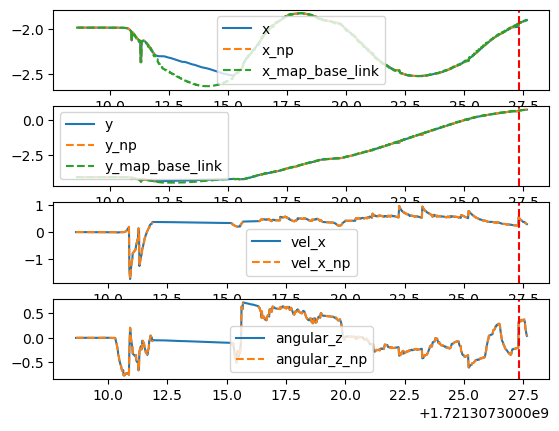

In [1]:
from social_evaluation.utils import *
from matplotlib import pyplot as plt
import numpy as np

bag_path = get_bag_path('exp_2', 'DWA', '/home/andrea/workspaces/appl_ws/bags', 1)
messages = get_messages_from_bag(bag_path, '/vicon/odom')
df_odometry = odometry_to_df(messages)
people_msgs = get_messages_from_bag(bag_path, '/vicon/people')
df_people = people_to_df(people_msgs)
tf_msgs = get_messages_from_bag(bag_path, '/tf')
df_tf = tf2_messages_to_df(tf_msgs)
goal_msgs = get_messages_from_bag(bag_path, '/objective')

goal = get_goal_position(goal_msgs)

time_goal_reached = time_goal_reached(df_odometry, goal, 0.5)

df = pd.merge(df_odometry, df_people, on='time', how='outer')
df.sort_values(by='time', inplace=True, ignore_index=True)

df_interpolated = df.interpolate(method='from_cubic_splines', limit_direction='both')

# print(check_if_simple_transform(df_tf, 'map','U_1.U_1'))
# trasform_matrix = get_transform_between_frames(df_tf, 'base_link', 'map', 1721311760.997747)
# print(ordered_seq)
# print(df_tf.loc[ordered_seq])
# print(get_pose_data_from_transform(trasform_matrix))
transformations_map_base_link = []
for timestamp in filter_df_by_time(df_tf)['time']:
    
    transformations_map_base_link.append(
        pd.Series(
            {
                'time':timestamp,
                **get_pose_data_from_transform(get_transform_between_frames(df_tf, 'map', 'base_link', timestamp))}
                                               )
            )


df_map_base_link = pd.DataFrame(transformations_map_base_link)

# show interpolated data

fig, ax = plt.subplots(4, 1)

time = np.array(df_interpolated['time'])
x = np.array(df_interpolated['x'])
time_np = np.array(df['time'])
time_map_base_link = np.array(df_map_base_link['time'])
x_map_base_link = np.array(df_map_base_link['position_x'])
x_np = np.array(df['x'])
y = np.array(df_interpolated['y'])
y_np = np.array(df['y'])
y_map_base_link = np.array(df_map_base_link['position_y'])
vel_x = np.array(df_interpolated['velocity_x'])
vel_x_np = np.array(df['velocity_x'])
angular_z = np.array(df_interpolated['angular_velocity_z'])
angular_z_np = np.array(df['angular_velocity_z'])
# y = np.array(df_interpolated['y'])
ax[0].plot(time, x, label='x')
ax[0].plot(time_np, x_np, label='x_np', linestyle='--')
ax[0].plot(time_map_base_link, x_map_base_link, label='x_map_base_link', linestyle='--')
ax[0].axvline(x=time_goal_reached, color='r', linestyle='--')
ax[0].legend()
ax[1].plot(time, y, label='y')
ax[1].plot(time_np, y_np, label='y_np', linestyle='--')
ax[1].plot(time_map_base_link, y_map_base_link, label='y_map_base_link', linestyle='--')
ax[1].axvline(x=time_goal_reached, color='r', linestyle='--')
ax[1].legend()
ax[2].plot(time, vel_x, label='vel_x')
ax[2].plot(time_np, vel_x_np, label='vel_x_np', linestyle='--')
ax[2].axvline(x=time_goal_reached, color='r', linestyle='--')
ax[2].legend()
ax[3].plot(time, angular_z, label='angular_z')
ax[3].plot(time_np, angular_z_np, label='angular_z_np', linestyle='--')
ax[3].axvline(x=time_goal_reached, color='r', linestyle='--')
plt.legend()


In [2]:
from social_evaluation.utils.utils import *
from tf_transformations import euler_from_quaternion, compose_matrix, decompose_matrix, quaternion_from_euler, inverse_matrix


